# ECOBICI — 05. Recomendación final, análisis de sensibilidad e impacto ambiental

En esta etapa se integran los resultados obtenidos
durante el desarrollo del modelo estocástico, la
optimización de la política de redistribución y
la simulación de diferentes escenarios de demanda.

El objetivo es evaluar el desempeño de la estrategia
propuesta, analizar su sensibilidad ante cambios en
los parámetros del modelo y formular una recomendación
final para mejorar el funcionamiento de ECOBICI
dentro de la subred estudiada.

Adicionalmente, se analiza el impacto ambiental
potencial de sustituir los camiones de redistribución
por bicicletas de carga convencionales con remolques
de cuatro espacios.

## 1. Integración de resultados

Se recuperan los resultados de las etapas anteriores
para mantener la consistencia del análisis y evitar
repetir los modelos previamente desarrollados.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

ruta_tablas = Path("outputs/tablas")

### 1.1 Selección de fuentes de información

Para el análisis final se utilizan los resultados
generados durante las etapas anteriores del proyecto.

| Archivo | Información utilizada |
|---|---|
| tasas_modelo.csv | Tasas de retiro y devolución |
| lotes.csv | Tamaño promedio de los lotes |
| camion_politicas.csv | Desempeño de las políticas |
| camion_frontera.csv | Sensibilidad de la optimización |
| camion_actual.csv | Redistribución actual |
| camion_propuesta.csv | Redistribución optimizada |
| sim_escenarios.csv | Escenarios de demanda |
| sim_variacion_dias.csv | Variabilidad entre días |
| sim_criterios.csv | Criterios de evaluación |

In [5]:
archivos = {
    "tasas": "tasas_modelo.csv",
    "lotes": "lotes.csv",
    "politicas": "camion_politicas.csv",
    "frontera": "camion_frontera.csv",
    "actual": "camion_actual.csv",
    "propuesta": "camion_propuesta.csv",
    "escenarios": "sim_escenarios.csv",
    "variacion_dias": "sim_variacion_dias.csv",
    "criterios": "sim_criterios.csv"
}

datos = {}

for nombre, archivo in archivos.items():
    datos[nombre] = pd.read_csv(ruta_tablas / archivo)

### 1.2 Exploración de los resultados previos

Para evaluar el desempeño del sistema se consideran
los siguientes indicadores:

- Rechazos por falta de bicicletas.
- Rechazos por falta de espacios disponibles.
- Rechazos totales.
- Cantidad de bicicletas redistribuidas.
- Porcentaje de demanda atendida.

Estos indicadores permiten determinar si la política
propuesta mejora la disponibilidad de bicicletas
y espacios sin incrementar considerablemente
los recursos destinados a la redistribución.

In [6]:
resumen_politicas = datos["politicas"].groupby("política")[
    ["sin bici", "sin dock", "rechazos",
     "bicis dejadas", "bicis sacadas"]
].sum()

resumen_politicas["movimientos totales"] = (
    resumen_politicas["bicis dejadas"] +
    resumen_politicas["bicis sacadas"]
)

display(resumen_politicas.round(2))

,sin bici,sin dock,rechazos,bicis dejadas,bicis sacadas,movimientos totales
política,,,,,,
actual,106.27,100.53,206.80,356.99,650.89,1007.88
propuesta,56.31,46.34,102.66,354.46,650.10,1004.56
sin camión,401.27,687.70,1088.97,0.00,0.00,0.00


### 1.3 Comparación de políticas de redistribución

Se comparan tres alternativas de operación:

- Sin redistribución de bicicletas.
- Política de redistribución actual.
- Política de redistribución optimizada.

Para cuantificar la mejora obtenida se calcula
el porcentaje de reducción de rechazos:

$$
R = \frac{R_{actual}-R_{propuesta}}{R_{actual}}\times 100
$$

Donde:

- $R_{actual}$: rechazos bajo la política actual.
- $R_{propuesta}$: rechazos bajo la política propuesta.

También se compara la cantidad de movimientos de
bicicletas necesarios para implementar cada política.

In [7]:
rechazos_actual = resumen_politicas.loc["actual", "rechazos"]
rechazos_propuesta = resumen_politicas.loc["propuesta", "rechazos"]

rechazos_evitados = rechazos_actual - rechazos_propuesta

reduccion_rechazos = (
    rechazos_evitados / rechazos_actual
) * 100

mov_actual = resumen_politicas.loc["actual", "movimientos totales"]
mov_propuesta = resumen_politicas.loc["propuesta", "movimientos totales"]

variacion_movimientos = (
    (mov_propuesta - mov_actual) / mov_actual
) * 100

print(f"Rechazos evitados por día: {rechazos_evitados:.2f}")
print(f"Reducción de rechazos: {reduccion_rechazos:.2f}%")
print(f"Variación de movimientos: {variacion_movimientos:.2f}%")

Rechazos evitados por día: 104.14
Reducción de rechazos: 50.36%
Variación de movimientos: -0.33%


### 1.4 Visualización de los resultados

Se presenta una comparación gráfica de los rechazos
por falta de bicicletas y espacios disponibles bajo
cada política de redistribución.

La gráfica permite identificar la alternativa
que presenta el mejor desempeño operativo.

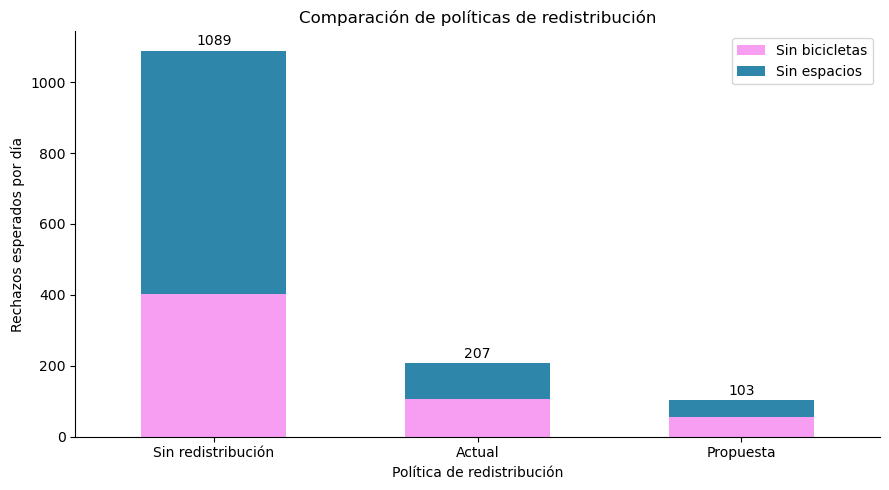

In [9]:
orden = ["sin camión", "actual", "propuesta"]

comparacion = resumen_politicas.reindex(orden)

ax = comparacion[["sin bici", "sin dock"]].plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#F79EF3", "#2e86ab"],
    width=0.55
)

for i, total in enumerate(comparacion["rechazos"]):
    ax.text(i, total + 15, f"{total:.0f}", ha="center")

ax.set_title("Comparación de políticas de redistribución")
ax.set_xlabel("Política de redistribución")
ax.set_ylabel("Rechazos esperados por día")

ax.set_xticklabels(
    ["Sin redistribución", "Actual", "Propuesta"],
    rotation=0
)

ax.legend(["Sin bicicletas", "Sin espacios"])
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Interpretación de los resultados

La política de redistribución propuesta permite
reducir aproximadamente un 50% los rechazos diarios
respecto a la política actual.

Esta mejora se obtiene manteniendo prácticamente
la misma cantidad de movimientos de bicicletas,
lo que indica que una mejor planificación de la
redistribución puede mejorar el desempeño del
sistema sin incrementar significativamente
la cantidad de bicicletas manipuladas.

Por otro lado, eliminar la redistribución genera
un incremento considerable en los rechazos,
demostrando la importancia de esta actividad
para el funcionamiento de ECOBICI.

## 2. Análisis de sensibilidad

El análisis de sensibilidad permite evaluar cómo
cambia el desempeño del modelo cuando se modifican
sus parámetros y condiciones de operación.

Se analizan principalmente:

- Nivel de demanda de los usuarios.
- Capacidad de los vehículos de redistribución.
- Número máximo de visitas por estación.
- Penalización por movimientos de bicicletas.

El objetivo es identificar qué factores tienen
mayor influencia sobre los resultados y determinar
si las estrategias propuestas mantienen un buen
desempeño bajo diferentes condiciones.

### 2.1 Sensibilidad ante cambios en la demanda

Se utilizan los resultados de las simulaciones
realizadas en las etapas anteriores para evaluar
el comportamiento del sistema bajo tres escenarios:

- Demanda baja.
- Demanda base.
- Demanda alta.

Se comparan los rechazos promedio y el porcentaje
de demanda atendida bajo cada política de
redistribución.

In [10]:
orden_escenarios = ["baja", "base", "alta"]

sensibilidad_demanda = datos["escenarios"].pivot(
    index="escenario",
    columns="política",
    values="rechazos (media)"
).reindex(orden_escenarios)

sensibilidad_demanda["rechazos evitados"] = (
    sensibilidad_demanda["actual"] -
    sensibilidad_demanda["propuesta"]
)

sensibilidad_demanda["reducción (%)"] = (
    sensibilidad_demanda["rechazos evitados"] /
    sensibilidad_demanda["actual"] * 100
)

display(sensibilidad_demanda.round(2))

política,actual,propuesta,propuesta (camión de 40),sin camión,rechazos evitados,reducción (%)
escenario,,,,,,
baja,232.7,115.3,201.6,1056.4,117.4,50.45
base,270.6,126.4,226.2,1092.2,144.2,53.29
alta,410.9,187.7,339.0,1286.5,223.2,54.32


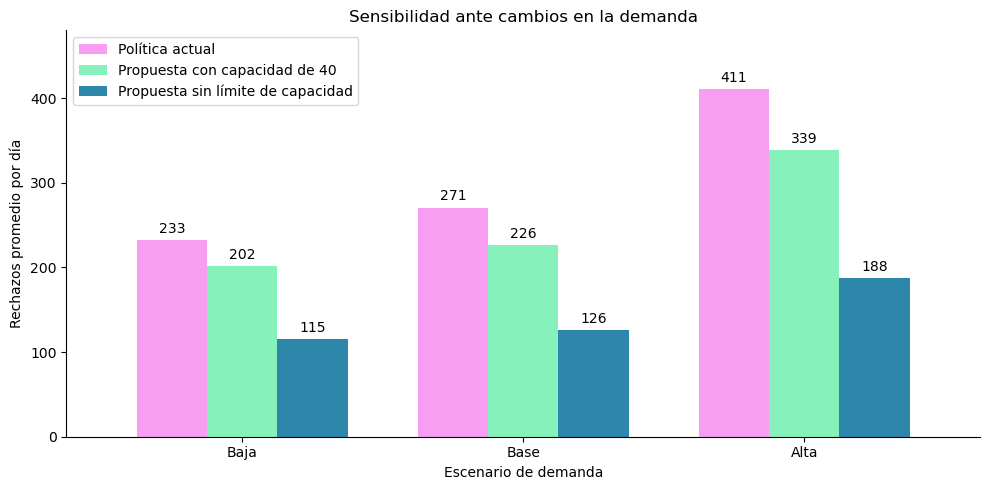

In [12]:
columnas = [
    "actual",
    "propuesta (camión de 40)",
    "propuesta"
]

ax = sensibilidad_demanda[columnas].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#F79EF3", "#87f1bc", "#2e86ab"],
    width=0.75
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", padding=3)

ax.set_title("Sensibilidad ante cambios en la demanda")
ax.set_xlabel("Escenario de demanda")
ax.set_ylabel("Rechazos promedio por día")
ax.set_xticklabels(["Baja", "Base", "Alta"], rotation=0)

ax.legend([
    "Política actual",
    "Propuesta con capacidad de 40",
    "Propuesta sin límite de capacidad"
])

ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, 480)

plt.tight_layout()
plt.show()

In [14]:
demanda_atendida = datos["escenarios"].pivot(
    index="escenario",
    columns="política",
    values="% demanda atendida"
).reindex(orden_escenarios)

display(demanda_atendida.round(2))

política,actual,propuesta,propuesta (camión de 40),sin camión
escenario,,,,
baja,92.3,96.2,93.3,65.2
base,91.3,96.0,92.8,64.9
alta,88.3,94.7,90.3,63.3


#### Interpretación de los resultados

La política optimizada presenta una reducción de
rechazos superior al 50% en los tres escenarios
cuando no se limita la capacidad por visita.

Incluso bajo condiciones de demanda alta, la
estrategia mantiene un mejor desempeño que la
política actual.

Al incorporar una capacidad máxima de 40 bicicletas
por visita, la mejora disminuye, aunque la propuesta
continúa presentando menos rechazos que la política
actual en los tres escenarios.

Esto demuestra que la capacidad de redistribución
es un factor importante para el desempeño del sistema.

### 2.2 Sensibilidad ante cambios en la capacidad de transporte

La capacidad de los vehículos determina cuántas
bicicletas pueden redistribuirse durante cada visita.

A partir de los resultados de camion.ipynb se
evalúa el desempeño de la política optimizada
considerando diferentes límites de capacidad.

Este análisis servirá como referencia para evaluar
la alternativa de bicicletas de carga con capacidad
de seis bicicletas por vehículo.

In [15]:
# Resultados obtenidos de camion.ipynb
sensibilidad_capacidad = pd.DataFrame({
    "Capacidad por visita": [
        "20", "30", "40", "60", "Sin límite"
    ],
    "Rechazos": [454, 311, 197, 105, 103],
    "Movimientos": [651, 795, 910, 1003, 1005]
})

sensibilidad_capacidad["Reducción (%)"] = (
    (rechazos_actual - sensibilidad_capacidad["Rechazos"])
    / rechazos_actual * 100
)

display(sensibilidad_capacidad.round(2))

,Capacidad por visita,Rechazos,Movimientos,Reducción (%)
0,20,454,651,-119.54
1,30,311,795,-50.39
2,40,197,910,4.74
3,60,105,1003,49.23
4,Sin límite,103,1005,50.19


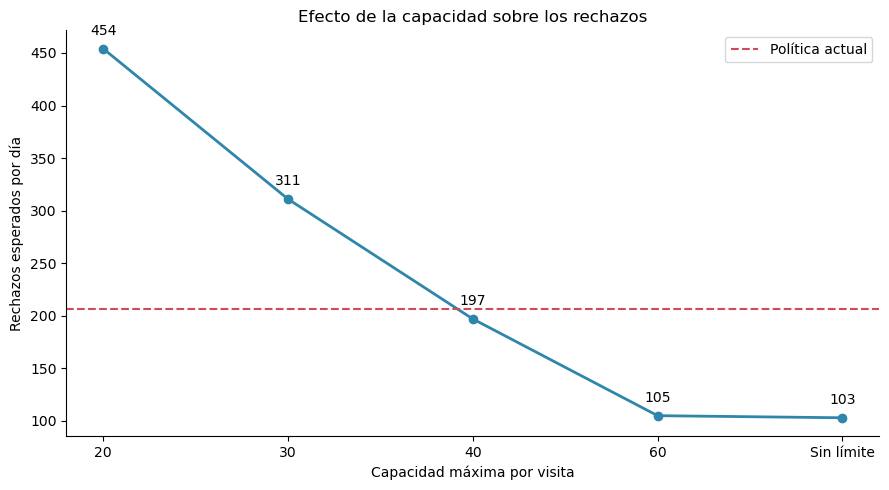

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    sensibilidad_capacidad["Capacidad por visita"],
    sensibilidad_capacidad["Rechazos"],
    marker="o",
    linewidth=2,
    color="#2e86ab"
)

ax.axhline(
    rechazos_actual,
    linestyle="--",
    color="#d1495b",
    label="Política actual"
)

for i, valor in enumerate(sensibilidad_capacidad["Rechazos"]):
    ax.annotate(
        str(valor),
        (i, valor),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Efecto de la capacidad sobre los rechazos")
ax.set_xlabel("Capacidad máxima por visita")
ax.set_ylabel("Rechazos esperados por día")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Interpretación de los resultados

Una menor capacidad de transporte genera un
incremento en los rechazos del sistema cuando
se mantiene el mismo plan de visitas.

Con una capacidad de 40 bicicletas por visita,
la propuesta comienza a superar el desempeño
de la política actual entre las capacidades
evaluadas.

Este resultado es relevante para la implementación
de bicicletas de carga, ya que su capacidad de
seis bicicletas por vehículo podría requerir
una mayor frecuencia de visitas o un mayor
número de vehículos de redistribución.